**More on Convnets:**
- Implementing ResNet-34 CNN using pytorch

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms

In [2]:
from functools import partial

In [3]:
class ResidualUnit(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        DefaultConv2d = partial(
            nn.Conv2d, kernel_size=3, stride=1, padding=1, bias=False
        )
        self.main_layers = nn.Sequential(
            DefaultConv2d(in_channels, out_channels, stride=stride),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            DefaultConv2d(out_channels, out_channels),
            nn.BatchNorm2d(out_channels)
        )

        if stride > 1:
            self.skip_connection = nn.Sequential(
                DefaultConv2d(in_channels, out_channels, kernel_size=1, stride=stride, padding=0),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.skip_connection = nn.Identity()
    
    def forward(self, inputs):
        return F.relu(self.main_layers(inputs) + self.skip_connection(inputs))

In [4]:
[64] * 3 + [128] * 4 + [256] * 6 + [512] * 3

[64, 64, 64, 128, 128, 128, 128, 256, 256, 256, 256, 256, 256, 512, 512, 512]

In [5]:
class ResNet34(nn.Module):
    def __init__(self):
        super().__init__()
        layers = [
            nn.Conv2d(in_channels=3, out_channels=64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(num_features=64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        ]
        prev_filters = 64
        for filters in [64] * 3 + [128] * 4 + [256] * 6 + [512] * 3:
            stride = 1 if filters == prev_filters else 2
            layers.append(ResidualUnit(prev_filters, filters, stride=stride))
            prev_filters = filters
        
        layers += [
            nn.AdaptiveAvgPool2d(output_size=1),
            nn.Flatten(),
            nn.LazyLinear(10)
        ]

        self.resnet  = nn.Sequential(*layers)
    
    def forward(self, inputs):
        return self.resnet(inputs)

In [7]:
device = torch.device('mps' if torch.mps.is_available() else 'cpu')

In [8]:
torch.manual_seed(42)
model = ResNet34().to(device)
images = torch.randn(2,3,224,224).to(device)
model(images)

tensor([[ 0.1329,  0.1891,  0.1162, -0.9223, -0.0911,  0.0854,  0.6126,  0.0229,
          0.0838, -0.0496],
        [ 0.2894,  0.3137,  0.1142, -1.0163,  0.0233,  0.2133,  0.5497, -0.0836,
          0.1013,  0.0924]], device='mps:0', grad_fn=<LinearBackward0>)

**Using Torchvision's pretrained models:**

LOad only the architecture:

In [10]:
import torchvision

In [11]:
# load only the architecture without the pretrained weights
# simple ... just pass weights as None
model = torchvision.models.convnext_base(
    weights = None
).to(device)

In [12]:
print(model)

ConvNeXt(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 128, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((128,), eps=1e-06, elementwise_affine=True)
    )
    (1): Sequential(
      (0): CNBlock(
        (block): Sequential(
          (0): Conv2d(128, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=128)
          (1): Permute()
          (2): LayerNorm((128,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=128, out_features=512, bias=True)
          (4): GELU(approximate='none')
          (5): Linear(in_features=512, out_features=128, bias=True)
          (6): Permute()
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): CNBlock(
        (block): Sequential(
          (0): Conv2d(128, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=128)
          (1): Permute()
          (2): LayerNorm((128,), eps=1e-06, elementwise_affine=True)
          (3): Linear(

finding available weights:
- for the specific model: you can directly inspect its weight enum

In [14]:
from torchvision.models import ConvNeXt_Base_Weights
print(list(ConvNeXt_Base_Weights))

[ConvNeXt_Base_Weights.IMAGENET1K_V1]


Generic method for any torchvision model:

In [15]:
# instead of manually knowing the enum class name, use:
weights_enum = torchvision.models.get_model_weights(
    torchvision.models.convnext_base
)
print(weights_enum)
print(list(weights_enum))

<enum 'ConvNeXt_Base_Weights'>
[ConvNeXt_Base_Weights.IMAGENET1K_V1]


Inspecting information attached to weights:

In [16]:
weights = torchvision.models.ConvNeXt_Base_Weights.IMAGENET1K_V1
print(weights.meta)

{'min_size': (32, 32), 'categories': ['tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead', 'electric ray', 'stingray', 'cock', 'hen', 'ostrich', 'brambling', 'goldfinch', 'house finch', 'junco', 'indigo bunting', 'robin', 'bulbul', 'jay', 'magpie', 'chickadee', 'water ouzel', 'kite', 'bald eagle', 'vulture', 'great grey owl', 'European fire salamander', 'common newt', 'eft', 'spotted salamander', 'axolotl', 'bullfrog', 'tree frog', 'tailed frog', 'loggerhead', 'leatherback turtle', 'mud turtle', 'terrapin', 'box turtle', 'banded gecko', 'common iguana', 'American chameleon', 'whiptail', 'agama', 'frilled lizard', 'alligator lizard', 'Gila monster', 'green lizard', 'African chameleon', 'Komodo dragon', 'African crocodile', 'American alligator', 'triceratops', 'thunder snake', 'ringneck snake', 'hognose snake', 'green snake', 'king snake', 'garter snake', 'water snake', 'vine snake', 'night snake', 'boa constrictor', 'rock python', 'Indian cobra', 'green mamba', 'sea sn

You can retrieve the exact preprocessing pipeline associated with those weights:

In [18]:
preprocess = weights.transforms()
print(preprocess)

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


A complete pretrained setup is therefore:

In [19]:
# use the weights enum to get the weights
weights_enum = torchvision.models.get_model_weights(
    torchvision.models.convnext_base
)
print(list(weights_enum))


[ConvNeXt_Base_Weights.IMAGENET1K_V1]


In [20]:
weights = torchvision.models.ConvNeXt_Base_Weights.IMAGENET1K_V1

In [21]:
model = torchvision.models.convnext_base(
    weights = weights
).to(device)

preprocess = weights.transforms()

Downloading: "https://download.pytorch.org/models/convnext_base-6075fbad.pth" to /Users/blaise/.cache/torch/hub/checkpoints/convnext_base-6075fbad.pth


100%|██████████| 338M/338M [00:05<00:00, 65.7MB/s] 


Finding other model architectures:

In [22]:
from torchvision.models import list_models

models = list_models()

print(models)

['alexnet', 'convnext_base', 'convnext_large', 'convnext_small', 'convnext_tiny', 'deeplabv3_mobilenet_v3_large', 'deeplabv3_resnet101', 'deeplabv3_resnet50', 'densenet121', 'densenet161', 'densenet169', 'densenet201', 'efficientnet_b0', 'efficientnet_b1', 'efficientnet_b2', 'efficientnet_b3', 'efficientnet_b4', 'efficientnet_b5', 'efficientnet_b6', 'efficientnet_b7', 'efficientnet_v2_l', 'efficientnet_v2_m', 'efficientnet_v2_s', 'fasterrcnn_mobilenet_v3_large_320_fpn', 'fasterrcnn_mobilenet_v3_large_fpn', 'fasterrcnn_resnet50_fpn', 'fasterrcnn_resnet50_fpn_v2', 'fcn_resnet101', 'fcn_resnet50', 'fcos_resnet50_fpn', 'googlenet', 'inception_v3', 'keypointrcnn_resnet50_fpn', 'lraspp_mobilenet_v3_large', 'maskrcnn_resnet50_fpn', 'maskrcnn_resnet50_fpn_v2', 'maxvit_t', 'mc3_18', 'mnasnet0_5', 'mnasnet0_75', 'mnasnet1_0', 'mnasnet1_3', 'mobilenet_v2', 'mobilenet_v3_large', 'mobilenet_v3_small', 'mvit_v1_b', 'mvit_v2_s', 'quantized_googlenet', 'quantized_inception_v3', 'quantized_mobilenet_v2

In [23]:
list(torchvision.models.get_model_weights("convnext_base"))

[ConvNeXt_Base_Weights.IMAGENET1K_V1]

In [24]:
list(torchvision.models.get_model_weights("densenet161"))

[DenseNet161_Weights.IMAGENET1K_V1]

In [30]:
from sklearn.datasets import load_sample_images
import numpy as np
import matplotlib.pyplot as plt

In [28]:
sample_images = np.stack(load_sample_images()['images'])

In [29]:
sample_images.shape

(2, 427, 640, 3)

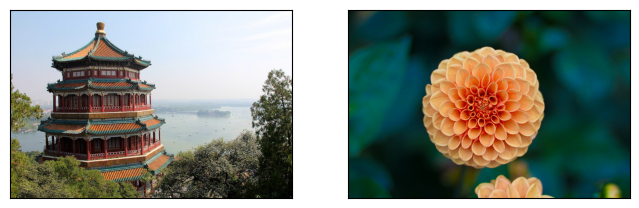

In [33]:
fig, ax = plt.subplots(1,2, figsize=(8,4))
ax[0].imshow(sample_images[0])
ax[1].imshow(sample_images[1])

ax[0].set_xticks([]); ax[0].set_yticks([]);
ax[1].set_xticks([]); ax[1].set_yticks([]);

In [35]:
# permute the sample images - from batch, height, width, channels to batch, channels, height, width as pytorch expects
sample_images = torch.tensor(sample_images, dtype=torch.float32)/255
sample_images_permuted = sample_images.permute(0, 3, 1, 2)
sample_images_permuted.shape

torch.Size([2, 3, 427, 640])

In [36]:
transform = weights.transforms()

In [37]:
transform

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

In [38]:
preprocessed_images = transform(sample_images_permuted)

In [39]:
model.eval()
# inference
with torch.no_grad():
    y_logits = model(preprocessed_images.to(device))

In [40]:
y_logits

tensor([[ 0.9411, -0.3203, -0.3067,  ...,  0.2111,  0.4626, -0.2570],
        [-0.6901, -0.6672, -0.8607,  ...,  0.9288,  4.1106, -0.8371]],
       device='mps:0')

In [41]:
y_logits.shape

torch.Size([2, 1000])

In [42]:
y_pred = torch.argmax(y_logits, dim=1)
y_pred

tensor([698, 985], device='mps:0')

In [43]:
weights.meta.keys()

dict_keys(['min_size', 'categories', 'recipe', '_docs', 'num_params', '_metrics', '_ops', '_file_size'])

In [44]:
class_names = weights.meta['categories']
[class_names[class_id] for class_id in y_pred]

['palace', 'daisy']

let's look at the model's top3 predictions:

In [45]:
y_top3_logits, y_top3_class_ids = y_logits.topk(k=3, dim=1)
[[class_names[class_id] for class_id in top3] for top3 in y_top3_class_ids]

[['palace', 'monastery', 'lakeside'], ['daisy', 'pot', 'ant']]

In [46]:
y_top3_logits.softmax(dim=1)

tensor([[0.8618, 0.1185, 0.0197],
        [0.8106, 0.0964, 0.0930]], device='mps:0')

**Pretrained model for transfer learning:**

Transfer learning:
- using the flowers 102 dataset; - which contains 102 categories of flowers and 10 images per category
- not lots of images so definitely will struggle with pretraining but transfer learning will work.

In [47]:
DefaultFlowers102 = partial(torchvision.datasets.Flowers102, root="datasets", transform = weights.transforms(), download=True)
train_set = DefaultFlowers102(split="train")
valid_set = DefaultFlowers102(split="val")
test_set = DefaultFlowers102(split="test")

100%|██████████| 345M/345M [00:05<00:00, 62.6MB/s] 
100%|██████████| 502/502 [00:00<00:00, 1.43MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 51.2MB/s]


In [48]:
# create the data loaders
from torch.utils.data import DataLoader

train_loader = DataLoader(train_set, batch_size=32, shuffle=32)
valid_loader = DataLoader(valid_set, batch_size=32)
test_loader = DataLoader(test_set, batch_size=32)

In [49]:
# pass the class names manually
class_names = ['pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea', 'english marigold', 'tiger lily', 'moon orchid', 'bird of paradise', 'monkshood', 'globe thistle', 'snapdragon', "colt's foot", 'king protea', 'spear thistle', 'yellow iris', 'globe-flower', 'purple coneflower', 'peruvian lily', 'balloon flower', 'giant white arum lily', 'fire lily', 'pincushion flower', 'fritillary', 'red ginger', 'grape hyacinth', 'corn poppy', 'prince of wales feathers', 'stemless gentian', 'artichoke', 'sweet william', 'carnation', 'garden phlox', 'love in the mist', 'mexican aster', 'alpine sea holly', 'ruby-lipped cattleya', 'cape flower', 'great masterwort', 'siam tulip', 'lenten rose', 'barbeton daisy', 'daffodil', 'sword lily', 'poinsettia', 'bolero deep blue', 'wallflower', 'marigold', 'buttercup', 'oxeye daisy', 'common dandelion', 'petunia', 'wild pansy', 'primula', 'sunflower', 'pelargonium', 'bishop of llandaff', 'gaura', 'geranium', 'orange dahlia', 'pink-yellow dahlia?', 'cautleya spicata', 'japanese anemone', 'black-eyed susan', 'silverbush', 'californian poppy', 'osteospermum', 'spring crocus', 'bearded iris', 'windflower', 'tree poppy', 'gazania', 'azalea', 'water lily', 'rose', 'thorn apple', 'morning glory', 'passion flower', 'lotus', 'toad lily', 'anthurium', 'frangipani', 'clematis', 'hibiscus', 'columbine', 'desert-rose', 'tree mallow', 'magnolia', 'cyclamen', 'watercress', 'canna lily', 'hippeastrum', 'bee balm', 'ball moss', 'foxglove', 'bougainvillea', 'camellia', 'mallow', 'mexican petunia', 'bromelia', 'blanket flower', 'trumpet creeper', 'blackberry lily']

In [57]:
flowers_to_display[0]

(tensor([[[0.6549, 0.6549, 0.6588,  ..., 0.6314, 0.6275, 0.6235],
          [0.6392, 0.6431, 0.6549,  ..., 0.6392, 0.6353, 0.6235],
          [0.6157, 0.6235, 0.6314,  ..., 0.6627, 0.6549, 0.6392],
          ...,
          [0.6980, 0.7176, 0.6941,  ..., 0.4471, 0.4980, 0.4784],
          [0.6863, 0.7137, 0.6980,  ..., 0.4941, 0.5020, 0.5137],
          [0.6745, 0.7098, 0.7059,  ..., 0.4784, 0.4706, 0.5059]],
 
         [[0.5686, 0.5765, 0.5922,  ..., 0.5922, 0.5882, 0.5843],
          [0.5412, 0.5569, 0.5765,  ..., 0.6000, 0.5961, 0.5961],
          [0.5176, 0.5373, 0.5529,  ..., 0.6235, 0.6157, 0.6118],
          ...,
          [0.5647, 0.6000, 0.6000,  ..., 0.2941, 0.3451, 0.3255],
          [0.5529, 0.5961, 0.6039,  ..., 0.3373, 0.3451, 0.3529],
          [0.5412, 0.5922, 0.6118,  ..., 0.3098, 0.3137, 0.3451]],
 
         [[0.7176, 0.7216, 0.7333,  ..., 0.7255, 0.7216, 0.7176],
          [0.6941, 0.7059, 0.7216,  ..., 0.7333, 0.7294, 0.7255],
          [0.6706, 0.6863, 0.6980,  ...,

In [ ]:
sorted({y: img for img, y in flowers_to_display}.items())

torch.Size([3, 200, 200])

In [66]:
len(sorted({y: img for img, y in flowers_to_display}.items()))

102

In [67]:
len(flowers_to_display)

1020

In [74]:
z = {1: 'blaise', 1: 'marvin', 2: 'rusoke'}

In [77]:
z

{1: 'marvin', 2: 'rusoke'}

In [75]:
sorted?

Signature: sorted(iterable, /, *, key=None, reverse=False)
Docstring:
Return a new list containing all items from the iterable in ascending order.

A custom key function can be supplied to customize the sort order, and the
reverse flag can be set to request the result in descending order.
Type:      builtin_function_or_method

In [76]:
sorted(z.items())

[(1, 'marvin'), (2, 'rusoke')]

In [63]:
len(flowers_to_display)

1020

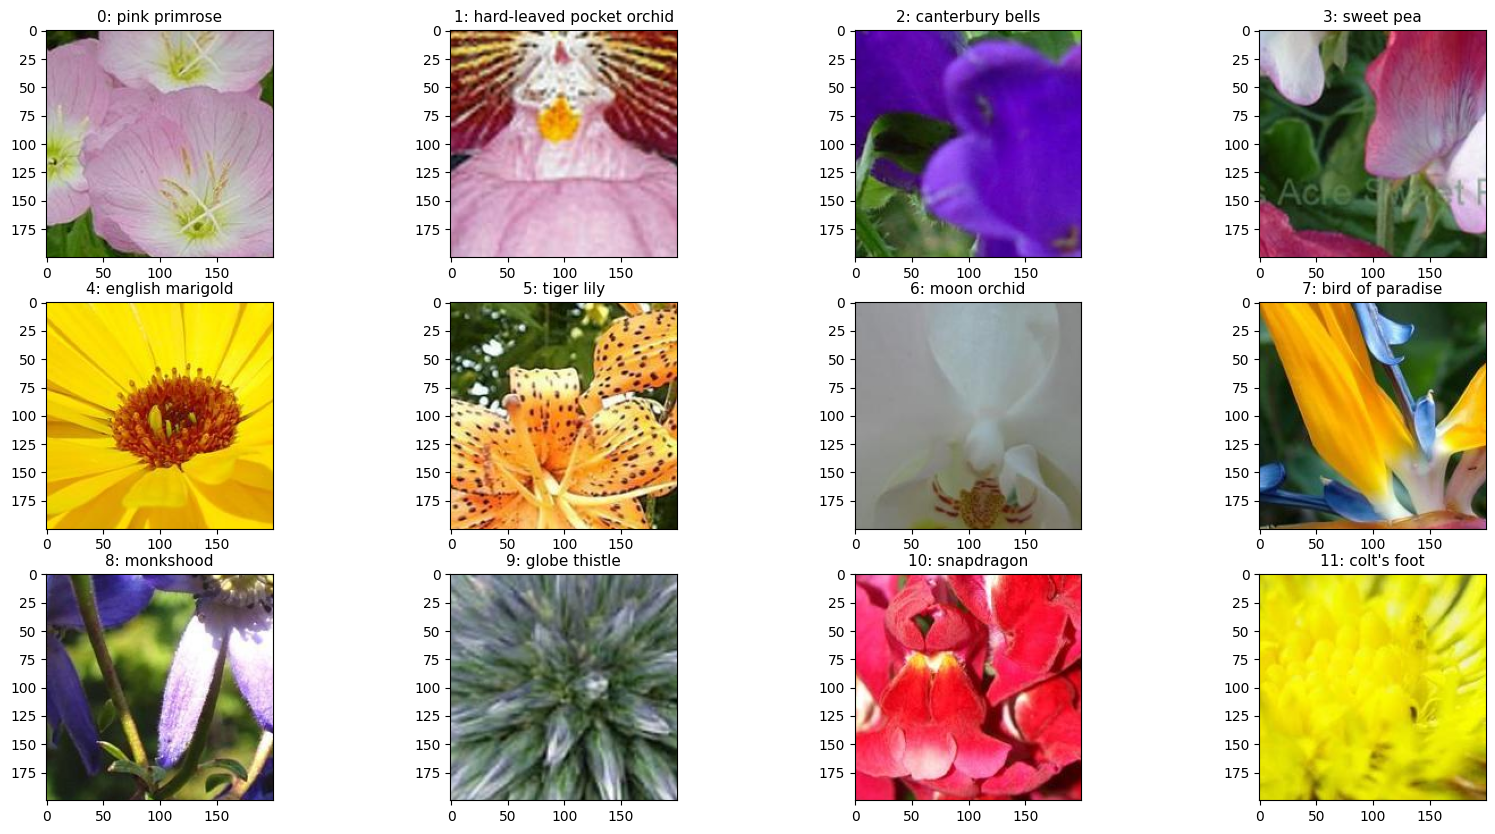

In [80]:
# extra code - displays the first image of classes 0 to 11 in the train set

transform = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.CenterCrop(200)
])

flowers_to_display = DefaultFlowers102(split='train', transform=transform)

sample_flowers = sorted({y: img for img,y in flowers_to_display}.items())[:12]

plt.figure(figsize=(20,10))
for class_id, image in sample_flowers:
    if class_id == 12: break
    plt.subplot(3, 4, class_id + 1)
    plt.imshow(image.numpy().transpose(1,2,0))
    plt.title(f"{class_id}: {class_names[class_id]}", fontsize=11)

plt.show()


Now, 
- lets adapt our pretrained ConvNeXt-base model to this dataset.
- change the model's final layers from the original 1000 to 102 classes in this flowers dataset

can inspect models using named_children func

In [50]:
for name, module in model.named_children():
    print(name, '->', module)

features -> Sequential(
  (0): Conv2dNormActivation(
    (0): Conv2d(3, 128, kernel_size=(4, 4), stride=(4, 4))
    (1): LayerNorm2d((128,), eps=1e-06, elementwise_affine=True)
  )
  (1): Sequential(
    (0): CNBlock(
      (block): Sequential(
        (0): Conv2d(128, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=128)
        (1): Permute()
        (2): LayerNorm((128,), eps=1e-06, elementwise_affine=True)
        (3): Linear(in_features=128, out_features=512, bias=True)
        (4): GELU(approximate='none')
        (5): Linear(in_features=512, out_features=128, bias=True)
        (6): Permute()
      )
      (stochastic_depth): StochasticDepth(p=0.0, mode=row)
    )
    (1): CNBlock(
      (block): Sequential(
        (0): Conv2d(128, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=128)
        (1): Permute()
        (2): LayerNorm((128,), eps=1e-06, elementwise_affine=True)
        (3): Linear(in_features=128, out_features=512, bias=True)
        (4):

In [51]:
[name for name, child in model.named_children()]

['features', 'avgpool', 'classifier']

the features module is the main part of the model which includes all layers except for the global average pooling layer and the model's head (classifier)

In [52]:
# taking a closer look at the head (classifier)
model.classifier

Sequential(
  (0): LayerNorm2d((1024,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=1024, out_features=1000, bias=True)
)

In [53]:
# as can be seen the classifier is a sequential module composed of a layer normaliszation layer, a flatten layer and a linear layer with 1024 outputs. we replace the final linear layer
n_classes = 102 
model.classifier[-1] = nn.Linear(1024, n_classes).to(device)

In [81]:
for param in model.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = True

In [86]:
z = torch.randn(5,10)

In [87]:
z.shape

torch.Size([5, 10])

In [90]:
torch.argmax(z, dim=1).sum()

tensor(32)

In [94]:
optimizer = torch.optim.AdamW(model.parameters())
criterion = nn.CrossEntropyLoss()

epochs = 5

def train(epochs):
    train_loss = [0] * epochs
    train_acc = [0] * epochs
    val_loss = [0] * epochs
    val_acc = [0] * epochs

    
    for epoch in range(epochs):
        # training loop
        model.train()
        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            
            # zero gradients
            optimizer.zero_grad()
            # forward pass
            out = model(x_batch)
            # compute the loss
            loss = criterion(out, y_batch)
            # back propagation
            loss.backward()
            # optimize
            optimizer.step()
        
        # evaluation
        model.eval()
        with torch.no_grad():
            for x_batch, y_batch in valid_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                out = model(x_batch)
                loss = criterion(out, y_batch)

                val_loss[epoch] += loss.item() * y_batch.shape[0]

                # track the accuracy
                val_acc[epoch] += (torch.argmax(out, dim=1).view(-1) == y_batch.view(-1)).float().sum().item()
            
            val_loss[epoch] /= len(valid_loader.dataset)
            val_acc[epoch] /= len(valid_loader.dataset)

            for x_batch, y_batch in train_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                out = model(x_batch)
                loss = criterion(out, y_batch)

                train_loss[epoch] += loss.item() * y_batch.shape[0]
                train_acc[epoch] += (torch.argmax(out, dim=1).view(-1) == y_batch.view(-1)).float().sum().item()
            
            train_loss[epoch] /= len(train_loader.dataset)
            train_acc[epoch] /= len(train_loader.dataset)
    
        print(f"Epoch: {epoch+1} | Train Accuracy: {train_acc[epoch]} | Train Loss: {train_loss[epoch]} | Valid Acc: {val_acc[epoch]} | Val Loss: {val_loss[epoch]}")

    return train_loss, train_acc, val_loss, val_acc

In [95]:
hist = train(5)

Epoch: 1 | Train Accuracy: 0.8215686274509804 | Train Loss: 2.678649864944757 | Valid Acc: 0.6529411764705882 | Val Loss: 2.9543538252512613
Epoch: 2 | Train Accuracy: 0.9205882352941176 | Train Loss: 1.828127474410861 | Valid Acc: 0.7970588235294118 | Val Loss: 2.2168377109602386
Epoch: 3 | Train Accuracy: 0.9529411764705882 | Train Loss: 1.2851928715612375 | Valid Acc: 0.8450980392156863 | Val Loss: 1.7379191076054292
Epoch: 4 | Train Accuracy: 0.9686274509803922 | Train Loss: 0.9437018906368929 | Valid Acc: 0.8539215686274509 | Val Loss: 1.4306823454651179
Epoch: 5 | Train Accuracy: 0.9725490196078431 | Train Loss: 0.7194465136995503 | Valid Acc: 0.8676470588235294 | Val Loss: 1.216339992541893


the abve looks like it is overfitting.
- perhaps next time try data augmentation on the training images.
- this showever must all be done before running the imagenet normalization step

In [96]:
preprocess

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

In [ ]:
# the normalization can be picked up from the above model's Normalization metrics specified above
# this can be passed to a normalize function as: transforms.normalize(mean=[], std=[])

In [99]:
import torchvision.transforms.v2 as T

In [100]:
ToTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])

train_and_valid_data = torchvision.datasets.MNIST(
    root = "datasets", train = True, download=True, transform=ToTensor
)
test_data = torchvision.datasets.MNIST(
    root = "datasets", train=False, download=True, transform=ToTensor
)

torch.manual_seed(42)
train_data, valid_data = torch.utils.data.random_split(train_and_valid_data, [55_000, 5_000])

100%|██████████| 9.91M/9.91M [00:00<00:00, 10.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 271kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.59MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.19MB/s]


In [101]:
torch.manual_seed(42)
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=32)
test_loader = DataLoader(test_data, batch_size=32)

In [107]:
for m in model.modules():
    print(m)
    break

ConvNeXt(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 128, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((128,), eps=1e-06, elementwise_affine=True)
    )
    (1): Sequential(
      (0): CNBlock(
        (block): Sequential(
          (0): Conv2d(128, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=128)
          (1): Permute()
          (2): LayerNorm((128,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=128, out_features=512, bias=True)
          (4): GELU(approximate='none')
          (5): Linear(in_features=512, out_features=128, bias=True)
          (6): Permute()
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): CNBlock(
        (block): Sequential(
          (0): Conv2d(128, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=128)
          (1): Permute()
          (2): LayerNorm((128,), eps=1e-06, elementwise_affine=True)
          (3): Linear(

In [108]:
class MnistModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        self.dropout1 = nn.Dropout(0.25)
        self.fc1 = nn.Linear(1 * 28 * 28 * 32 // 2, 128)
        self.dropout2 = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)

        for m in self.modules():
            if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
    
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = self.pool(x)
        x = self.flatten(x)
        x = self.dropout1(x)
        x = F.relu(self.fc1(x))
        x = self.dropout2(x)
        return self.fc2(x)

In [109]:
torch.manual_seed(42)
mnist_model = MnistModel().to(device)

In [110]:
n_epochs = 10
optimizer = torch.optim.AdamW(mnist_model.parameters())
criterion = nn.CrossEntropyLoss()

def train(epochs, model = mnist_model):
    train_loss = [0] * epochs
    train_acc = [0] * epochs
    val_loss = [0] * epochs
    val_acc = [0] * epochs

    
    for epoch in range(epochs):
        # training loop
        model.train()
        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            
            # zero gradients
            optimizer.zero_grad()
            # forward pass
            out = model(x_batch)
            # compute the loss
            loss = criterion(out, y_batch)
            # back propagation
            loss.backward()
            # optimize
            optimizer.step()
        
        # evaluation
        model.eval()
        with torch.no_grad():
            for x_batch, y_batch in valid_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                out = model(x_batch)
                loss = criterion(out, y_batch)

                val_loss[epoch] += loss.item() * y_batch.shape[0]

                # track the accuracy
                val_acc[epoch] += (torch.argmax(out, dim=1).view(-1) == y_batch.view(-1)).float().sum().item()
            
            val_loss[epoch] /= len(valid_loader.dataset)
            val_acc[epoch] /= len(valid_loader.dataset)

            for x_batch, y_batch in train_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                out = model(x_batch)
                loss = criterion(out, y_batch)

                train_loss[epoch] += loss.item() * y_batch.shape[0]
                train_acc[epoch] += (torch.argmax(out, dim=1).view(-1) == y_batch.view(-1)).float().sum().item()
            
            train_loss[epoch] /= len(train_loader.dataset)
            train_acc[epoch] /= len(train_loader.dataset)
    
        print(f"Epoch: {epoch+1} | Train Accuracy: {train_acc[epoch]} | Train Loss: {train_loss[epoch]} | Valid Acc: {val_acc[epoch]} | Val Loss: {val_loss[epoch]}")

    return train_loss, train_acc, val_loss, val_acc

In [111]:
hist = train(10)

Epoch: 1 | Train Accuracy: 0.9865818181818182 | Train Loss: 0.04378867400078611 | Valid Acc: 0.9826 | Val Loss: 0.062123859120160344
Epoch: 2 | Train Accuracy: 0.9901272727272727 | Train Loss: 0.030848191451357507 | Valid Acc: 0.9876 | Val Loss: 0.05213038452416659
Epoch: 3 | Train Accuracy: 0.9934181818181819 | Train Loss: 0.020190036816126668 | Valid Acc: 0.9862 | Val Loss: 0.049792011350253594
Epoch: 4 | Train Accuracy: 0.9957818181818182 | Train Loss: 0.013638601709188979 | Valid Acc: 0.988 | Val Loss: 0.04831969572033267
Epoch: 5 | Train Accuracy: 0.9972545454545455 | Train Loss: 0.009430291452840902 | Valid Acc: 0.99 | Val Loss: 0.03654564033944625
Epoch: 6 | Train Accuracy: 0.9973272727272727 | Train Loss: 0.008606027595578962 | Valid Acc: 0.9906 | Val Loss: 0.040280548790181635
Epoch: 7 | Train Accuracy: 0.9980545454545454 | Train Loss: 0.00634079612903244 | Valid Acc: 0.9906 | Val Loss: 0.037383100059174466
Epoch: 8 | Train Accuracy: 0.9982727272727273 | Train Loss: 0.00550228